# Campus Coffee Sales Analysis

**Course assignment, Spring 2026**

This notebook analyzes one semester of point-of-sale transactions from three campus coffee shops (Green Street, Library Kiosk, and Research Park). The goal is to understand when and where revenue comes from, and to suggest staffing and menu changes.

Data: `campus_coffee_sales.csv` (one row per transaction line, January 5 to May 8, 2026).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

pio.renderers.default = 'plotly_mimetype+notebook_connected'
sns.set_theme(style='whitegrid')

## 1. Load and prepare the data

In [2]:
df = pd.read_csv('campus_coffee_sales.csv', parse_dates=['date'])
df['revenue'] = df['unit_price'] * df['quantity']
df['weekday'] = df['date'].dt.day_name()
df.head()

,transaction_id,date,hour,store,item,category,unit_price,quantity,revenue,weekday
0,100001,2026-01-05,11,Green Street,Breakfast Sandwich,Food,5.75,2,11.50,Monday
1,100002,2026-01-05,11,Green Street,Latte,Coffee,4.50,1,4.50,Monday
2,100003,2026-01-05,10,Green Street,Drip Coffee,Coffee,2.75,2,5.50,Monday
3,100004,2026-01-05,8,Green Street,Latte,Coffee,4.50,3,13.50,Monday
4,100005,2026-01-05,9,Green Street,Chai Latte,Tea,4.25,1,4.25,Monday


In [3]:
print(f"Rows: {len(df):,}")
print(f"Date range: {df['date'].min():%b %d} to {df['date'].max():%b %d, %Y}")
print(f"Total revenue: ${df['revenue'].sum():,.0f}")
df.groupby('store')['revenue'].sum().sort_values(ascending=False).round(0)

Rows: 13,829
Date range: Jan 05 to May 08, 2026
Total revenue: $83,046


store
Green Street     35434.0
Research Park    24729.0
Library Kiosk    22883.0
Name: revenue, dtype: float64

## 2. Weekly revenue

Revenue drops sharply during spring break (March 14 to 22) and rises during finals at the end of April.

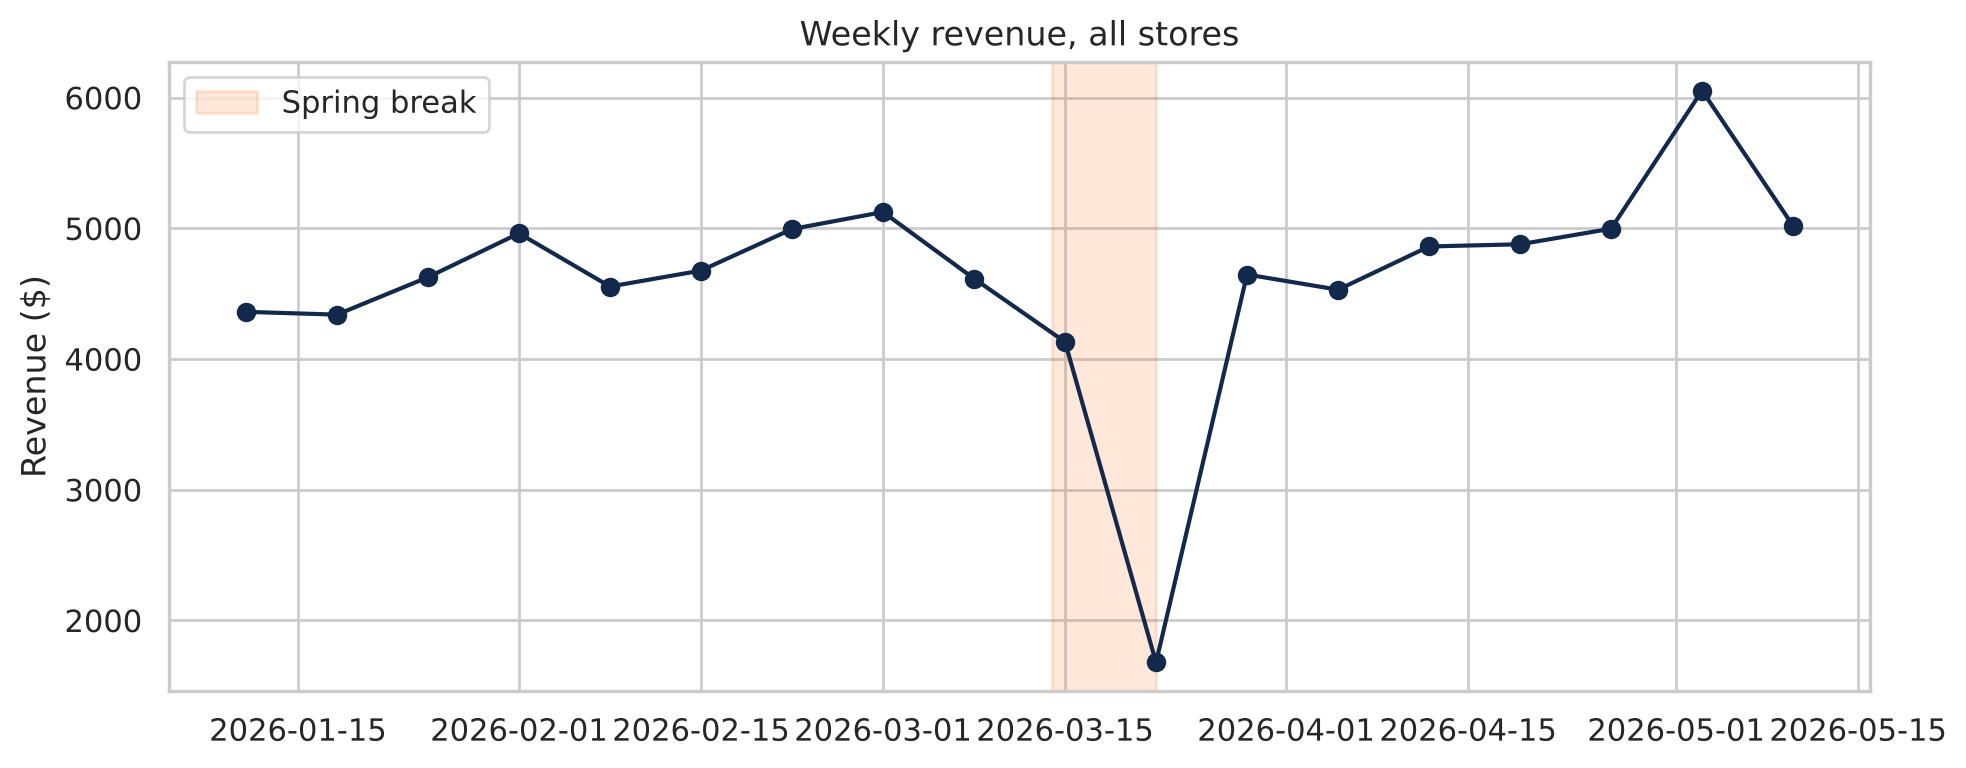

In [4]:
weekly = df.set_index('date').resample('W')['revenue'].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weekly.index, weekly.values, marker='o', color='#13294B')
ax.axvspan(pd.Timestamp('2026-03-14'), pd.Timestamp('2026-03-22'), color='#FF5F05', alpha=0.15, label='Spring break')
ax.set_title('Weekly revenue, all stores')
ax.set_ylabel('Revenue ($)')
ax.legend()
plt.tight_layout()
plt.show()

## 3. Revenue by category and store

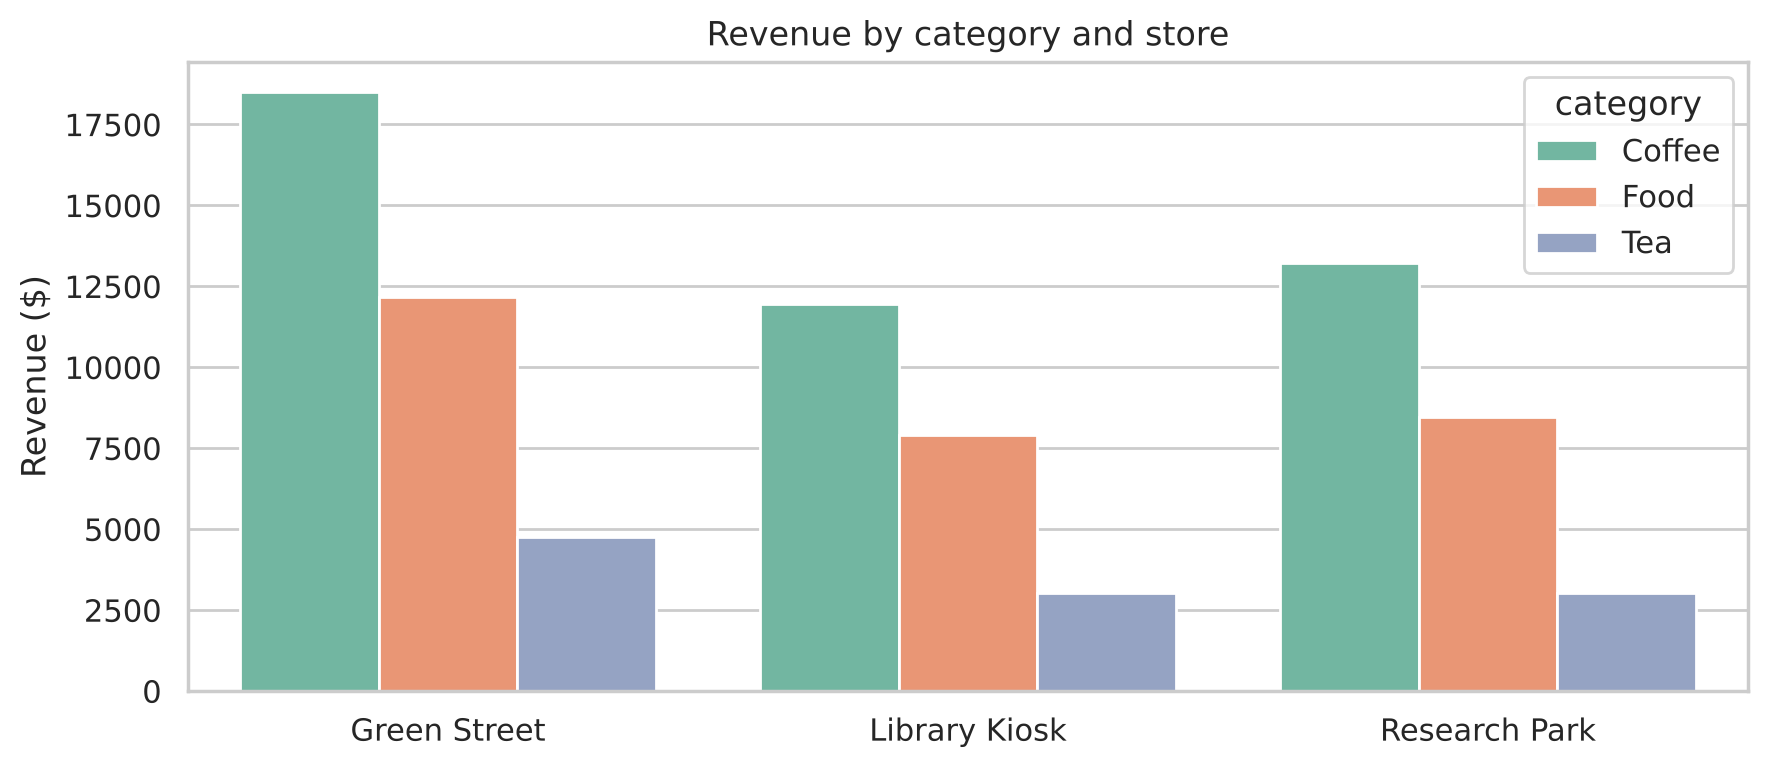

In [5]:
by_cat = df.groupby(['store', 'category'], as_index=False)['revenue'].sum()

plt.figure(figsize=(9, 4))
sns.barplot(data=by_cat, x='store', y='revenue', hue='category', palette='Set2')
plt.title('Revenue by category and store')
plt.ylabel('Revenue ($)')
plt.xlabel('')
plt.tight_layout()
plt.show()

## 4. When are the stores busiest?

The heatmap shows the average number of items sold per day for each hour and weekday, across all stores.

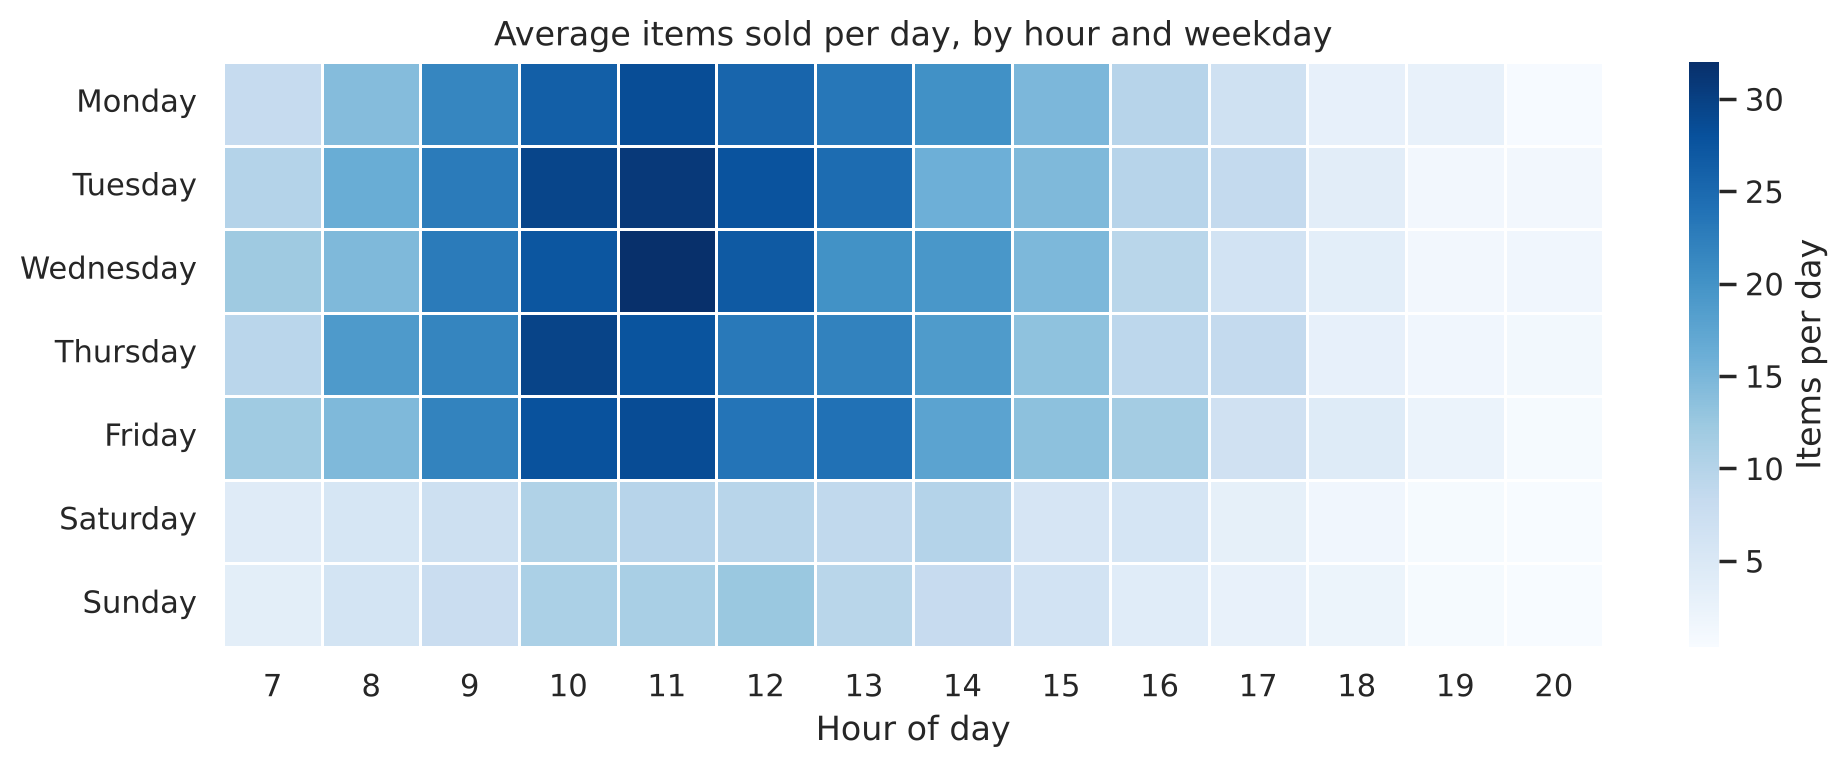

In [6]:
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
n_days = df.groupby('weekday')['date'].nunique()
heat = df.pivot_table(index='weekday', columns='hour', values='quantity', aggfunc='sum').div(n_days, axis=0).reindex(order)

plt.figure(figsize=(10, 4))
sns.heatmap(heat, cmap='Blues', linewidths=0.5, cbar_kws={'label': 'Items per day'})
plt.title('Average items sold per day, by hour and weekday')
plt.xlabel('Hour of day')
plt.ylabel('')
plt.tight_layout()
plt.show()

## 5. Interactive: daily revenue by store

Hover over the lines to see each day's revenue. Click a store in the legend to hide it.

In [7]:
daily = df.groupby(['date', 'store'], as_index=False)['revenue'].sum()
fig = px.line(daily, x='date', y='revenue', color='store',
              title='Daily revenue by store',
              labels={'revenue': 'Revenue ($)', 'date': ''})
fig.update_layout(hovermode='x unified')
fig.show()

## 6. Interactive: top items

In [8]:
items = df.groupby(['item', 'category'], as_index=False).agg(revenue=('revenue', 'sum'), units=('quantity', 'sum'))
items = items.sort_values('revenue')
fig = px.bar(items, x='revenue', y='item', color='category', orientation='h',
             hover_data={'units': ':,'},
             title='Revenue by menu item',
             labels={'revenue': 'Revenue ($)', 'item': ''})
fig.show()

## 7. Findings and recommendations

1. **Green Street brings in the most revenue**, about 43% of the total, and should get the most staff hours.
2. **Spring break cuts weekly revenue by about two thirds.** Shorter hours that week would save labor cost.
3. **Late morning, from about 10 to 12 on weekdays, is the busiest time.** The Library Kiosk peaks in the afternoon, so its staffing should start later.
4. **Lattes bring in the most revenue, followed by breakfast sandwiches and drip coffee.** A coffee and breakfast sandwich bundle could raise the average order.